In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load original dataset
df = pd.read_csv("../data/breast_cancer_wdbc.csv")

# Separate input and target
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

print("Dataset Shape:", df.shape)
print("Input Features:", X.shape)
print("Target Variable:", y.shape)

Dataset Shape: (569, 31)
Input Features: (569, 30)
Target Variable: (569,)


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

Training Data: (455, 30)
Testing Data: (114, 30)
Training Labels: (455,)
Testing Labels: (114,)


In [4]:
# Define Logistic Regression pipeline
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000, random_state=42))
])

# Define Random Forest
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Define SVM pipeline
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ))
])

# Train all three models
logistic_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)
svm_model.fit(X_train, y_train)

print("All three models trained successfully!")

All three models trained successfully!


c:\Users\U Krushna moorthy\OneDrive\Desktop\Breast_Cancer_Detection\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


In [5]:
# Generate predictions on test data

logistic_predictions = logistic_model.predict(X_test)

rf_predictions = random_forest_model.predict(X_test)

svm_predictions = svm_model.predict(X_test)

print("Predictions generated successfully!")

print("\nLogistic Regression Predictions:")
print(logistic_predictions[:10])

print("\nRandom Forest Predictions:")
print(rf_predictions[:10])

print("\nSVM Predictions:")
print(svm_predictions[:10])

Predictions generated successfully!

Logistic Regression Predictions:
[0 1 0 1 1 0 1 0 0 0]

Random Forest Predictions:
[0 1 0 1 0 0 1 0 0 0]

SVM Predictions:
[0 1 0 0 0 0 1 0 0 0]


In [6]:
# Get malignant probabilities
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

rf_probabilities = random_forest_model.predict_proba(X_test)[:, 1]

svm_probabilities = svm_model.predict_proba(X_test)[:, 1]


# Function to calculate evaluation metrics
def evaluate_model(name, y_true, predictions, probabilities):

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions),
        "Recall": recall_score(y_true, predictions),
        "F1 Score": f1_score(y_true, predictions),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }


# Evaluate all models
results = []

results.append(
    evaluate_model(
        "Logistic Regression",
        y_test,
        logistic_predictions,
        logistic_probabilities
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        rf_predictions,
        rf_probabilities
    )
)

results.append(
    evaluate_model(
        "SVM",
        y_test,
        svm_predictions,
        svm_probabilities
    )
)

# Display comparison
comparison_df = pd.DataFrame(results)

display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.9649,0.975,0.9286,0.9512,0.9960
1,Random Forest,0.9737,1.000,0.9286,0.9630,0.9929
2,SVM,0.9737,1.000,0.9286,0.9630,0.9947


In [7]:
import os

os.makedirs("../reports", exist_ok=True)

comparison_df.to_csv(
    "../reports/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


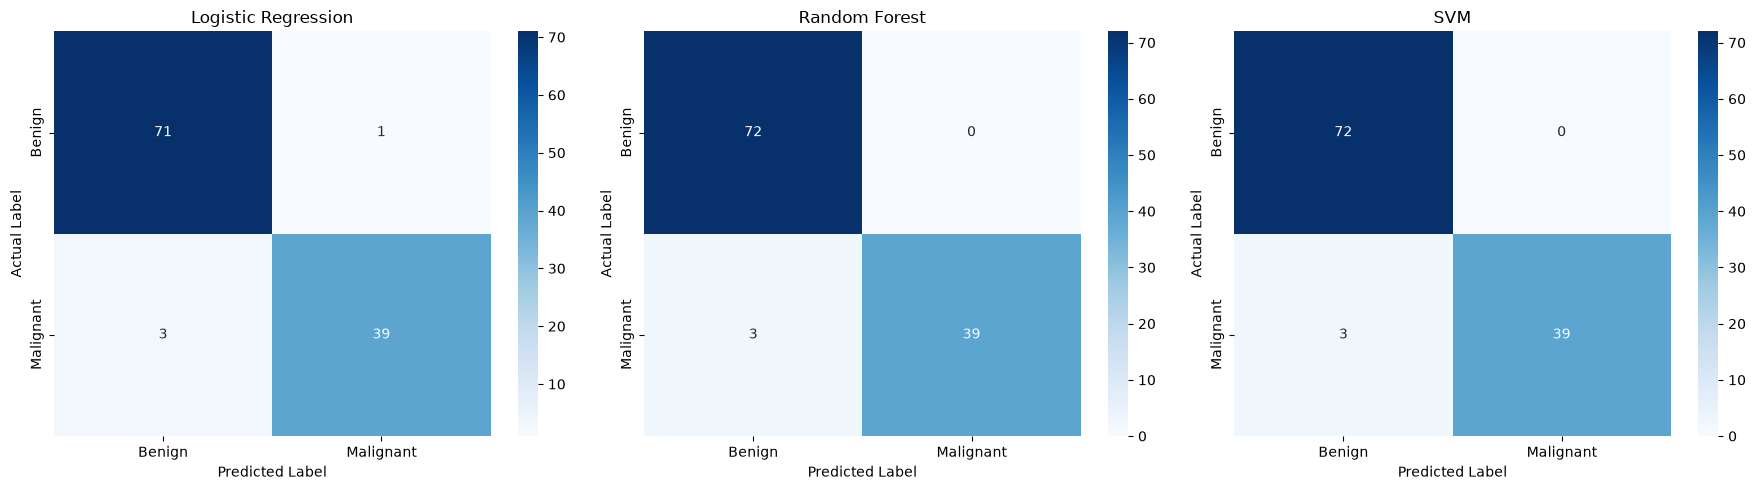

In [8]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model,
    "SVM": svm_model
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, model) in zip(axes, models.items()):

    predictions = model.predict(X_test)

    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Benign", "Malignant"],
        yticklabels=["Benign", "Malignant"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

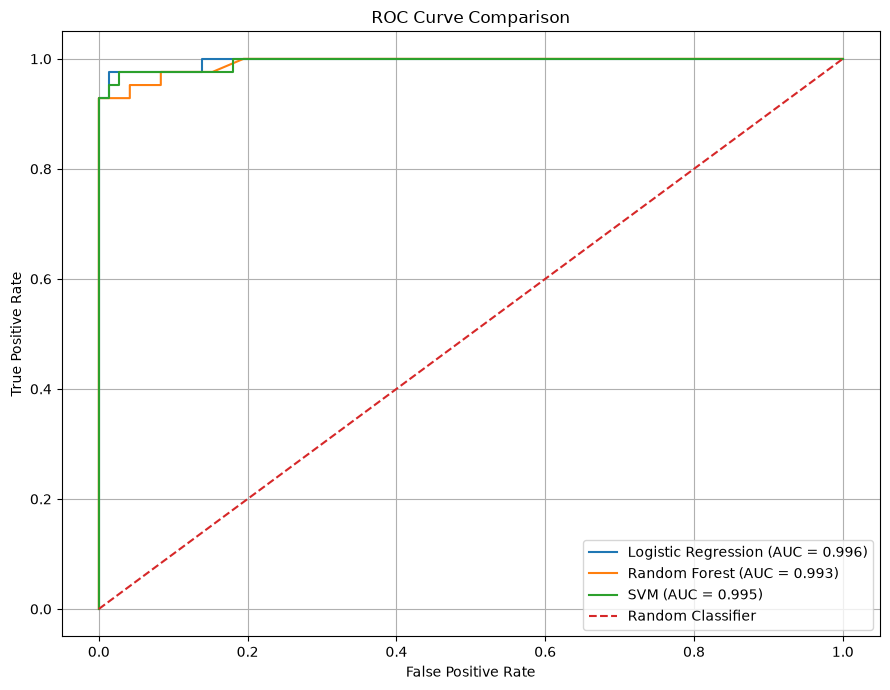

In [9]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(9, 7))

probabilities = {
    "Logistic Regression": logistic_probabilities,
    "Random Forest": rf_probabilities,
    "SVM": svm_probabilities
}

for name, probs in probabilities.items():

    fpr, tpr, thresholds = roc_curve(y_test, probs)

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

In [10]:
from sklearn.metrics import confusion_matrix

for name, model in models.items():

    predictions = model.predict(X_test)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions
    ).ravel()

    print(f"\n{name}")
    print("True Negatives:", tn)
    print("False Positives:", fp)
    print("False Negatives:", fn)
    print("True Positives:", tp)


Logistic Regression
True Negatives: 71
False Positives: 1
False Negatives: 3
True Positives: 39

Random Forest
True Negatives: 72
False Positives: 0
False Negatives: 3
True Positives: 39

SVM
True Negatives: 72
False Positives: 0
False Negatives: 3
True Positives: 39


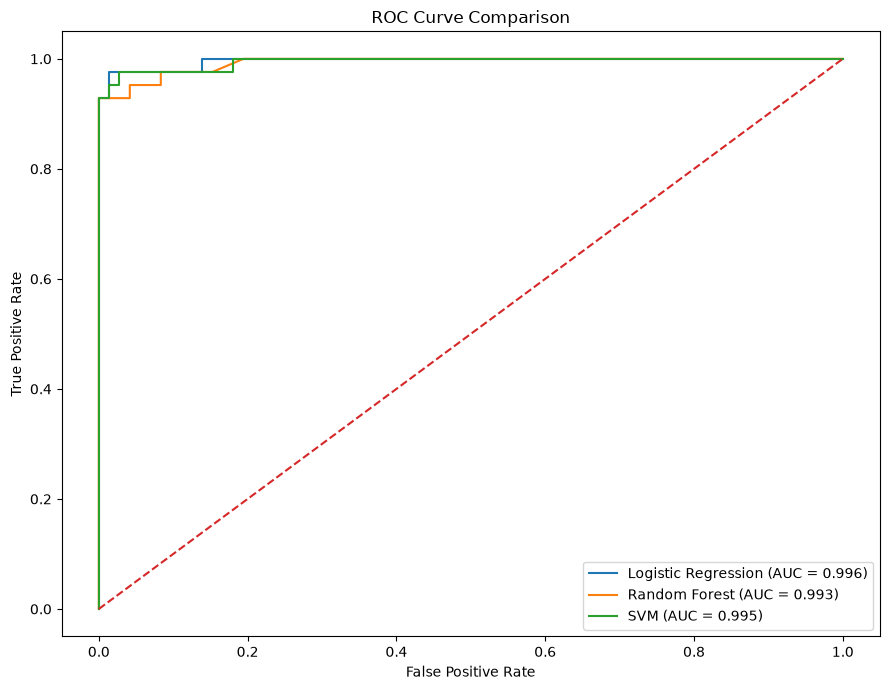

ROC curve saved successfully!


In [11]:
import os

os.makedirs("../reports", exist_ok=True)

# Save ROC curve
plt.figure(figsize=(9, 7))

for name, probs in probabilities.items():

    fpr, tpr, thresholds = roc_curve(y_test, probs)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc(fpr, tpr):.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.tight_layout()

plt.savefig("../reports/model_comparison_roc.png", dpi=300)
plt.show()

print("ROC curve saved successfully!")

In [12]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, fbeta_score

print("GridSearchCV libraries imported successfully!")

GridSearchCV libraries imported successfully!


In [13]:
# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Give greater importance to malignant recall
f2_scorer = make_scorer(
    fbeta_score,
    beta=2
)

print("Cross-validation strategy created!")

Cross-validation strategy created!


In [14]:
# Logistic Regression pipeline
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000, random_state=42))
])

# Hyperparameter combinations
lr_parameters = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"]
}

# Grid Search
lr_grid = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_parameters,
    scoring=f2_scorer,
    cv=cv,
    n_jobs=-1
)

lr_grid.fit(X_train, y_train)

print("Best Logistic Regression Parameters:")
print(lr_grid.best_params_)

print("Best Cross-Validation F2 Score:")
print(round(lr_grid.best_score_, 4))

Best Logistic Regression Parameters:
{'model__C': 1, 'model__class_weight': 'balanced'}
Best Cross-Validation F2 Score:
0.9599


c:\Users\U Krushna moorthy\OneDrive\Desktop\Breast_Cancer_Detection\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


In [15]:
rf_parameters = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "class_weight": [None, "balanced"]
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=rf_parameters,
    scoring=f2_scorer,
    cv=cv,
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest Parameters:")
print(rf_grid.best_params_)

print("Best Cross-Validation F2 Score:")
print(round(rf_grid.best_score_, 4))

Best Random Forest Parameters:
{'class_weight': None, 'max_depth': 5, 'min_samples_split': 2, 'n_estimators': 100}
Best Cross-Validation F2 Score:
0.9502


In [16]:
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(probability=True, random_state=42))
])

svm_parameters = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.01, 0.1],
    "model__kernel": ["rbf"]
}

svm_grid = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_parameters,
    scoring=f2_scorer,
    cv=cv,
    n_jobs=-1
)

svm_grid.fit(X_train, y_train)

print("Best SVM Parameters:")
print(svm_grid.best_params_)

print("Best Cross-Validation F2 Score:")
print(round(svm_grid.best_score_, 4))

Best SVM Parameters:
{'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
Best Cross-Validation F2 Score:
0.9657


In [17]:
# Collect best models
tuned_models = {
    "Tuned Logistic Regression": lr_grid.best_estimator_,
    "Tuned Random Forest": rf_grid.best_estimator_,
    "Tuned SVM": svm_grid.best_estimator_
}

# Display best parameters and CV scores
tuning_results = pd.DataFrame([
    {
        "Model": name,
        "Best Parameters": grid.best_params_,
        "CV F2 Score": grid.best_score_
    }
    for name, grid in [
        ("Logistic Regression", lr_grid),
        ("Random Forest", rf_grid),
        ("SVM", svm_grid)
    ]
])

display(tuning_results)

,Model,Best Parameters,CV F2 Score
0,Logistic Regression,"{'model__C': 1, 'model__class_weight': 'balanc...",0.959873
1,Random Forest,"{'class_weight': None, 'max_depth': 5, 'min_sa...",0.950242
2,SVM,"{'model__C': 10, 'model__gamma': 'scale', 'mod...",0.965677


In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    confusion_matrix
)

final_results = []

for name, model in tuned_models.items():

    # Predict class labels
    predictions = model.predict(X_test)

    # Predict malignant probabilities
    probabilities = model.predict_proba(X_test)[:, 1]

    # Calculate confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions
    ).ravel()

    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "F2 Score": fbeta_score(y_test, predictions, beta=2),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

final_comparison = pd.DataFrame(final_results)

display(final_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,F2 Score,ROC-AUC,TN,FP,FN,TP
0,Tuned Logistic Regression,0.9737,0.9756,0.9524,0.9639,0.9569,0.9954,71,1,2,40
1,Tuned Random Forest,0.9737,1.0000,0.9286,0.9630,0.9420,0.9950,72,0,3,39
2,Tuned SVM,0.9737,1.0000,0.9286,0.9630,0.9420,0.9927,72,0,3,39


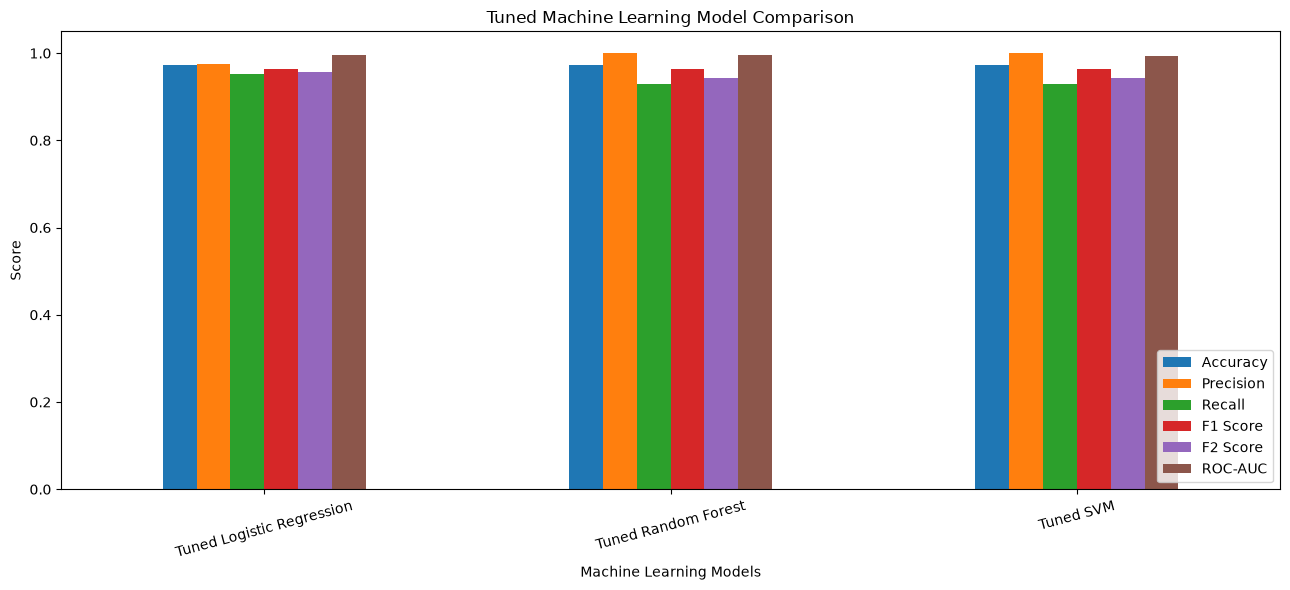

In [19]:
metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "F2 Score",
    "ROC-AUC"
]

plot_data = final_comparison.set_index("Model")[metrics_to_plot]

plot_data.plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Tuned Machine Learning Model Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

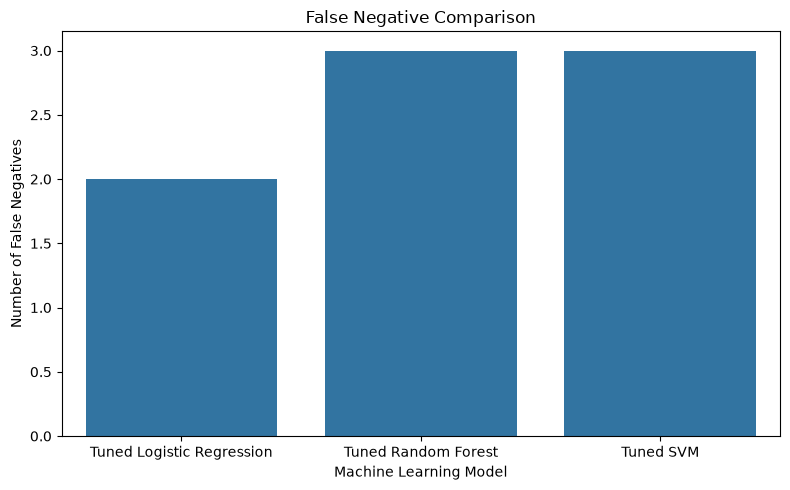

False Negative Counts:
                       Model  FN
0  Tuned Logistic Regression   2
1        Tuned Random Forest   3
2                  Tuned SVM   3


In [20]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=final_comparison,
    x="Model",
    y="FN"
)

plt.title("False Negative Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Number of False Negatives")
plt.tight_layout()
plt.show()

print("False Negative Counts:")
print(final_comparison[["Model", "FN"]])

In [21]:
import os

os.makedirs("../reports", exist_ok=True)

final_comparison.to_csv(
    "../reports/final_model_comparison.csv",
    index=False
)

print("Final model comparison saved successfully!")

Final model comparison saved successfully!


In [23]:
import joblib
import os

# Create model directory
os.makedirs("../models", exist_ok=True)

# Save tuned models separately
joblib.dump(
    lr_grid.best_estimator_,
    "../models/tuned_logistic_regression.pkl"
)

joblib.dump(
    rf_grid.best_estimator_,
    "../models/tuned_random_forest.pkl"
)

joblib.dump(
    svm_grid.best_estimator_,
    "../models/tuned_svm.pkl"
)

print("All tuned models saved successfully!")

All tuned models saved successfully!


In [24]:
model_metadata = {
    "feature_names": list(X.columns),
    "target_column": "diagnosis",
    "class_mapping": {
        0: "Benign",
        1: "Malignant"
    },
    "training_records": len(X_train),
    "testing_records": len(X_test),
    "random_state": 42,
    "test_size": 0.20
}

joblib.dump(
    model_metadata,
    "../models/model_metadata.pkl"
)

print("Model metadata saved successfully!")

Model metadata saved successfully!


In [25]:
final_comparison.to_csv(
    "../reports/final_model_comparison.csv",
    index=False
)

print("Final comparison report saved!")

Final comparison report saved!


In [26]:
display(final_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,F2 Score,ROC-AUC,TN,FP,FN,TP
0,Tuned Logistic Regression,0.9737,0.9756,0.9524,0.9639,0.9569,0.9954,71,1,2,40
1,Tuned Random Forest,0.9737,1.0000,0.9286,0.9630,0.9420,0.9950,72,0,3,39
2,Tuned SVM,0.9737,1.0000,0.9286,0.9630,0.9420,0.9927,72,0,3,39


In [27]:
import joblib
import os

# Create models directory
os.makedirs("../models", exist_ok=True)

# Get the best Logistic Regression model
final_model = lr_grid.best_estimator_

# Create model artifact
model_artifact = {
    "model": final_model,
    "model_name": "Tuned Logistic Regression",
    "feature_names": list(X.columns),
    "threshold": 0.5,
    "default_values": X_train.median().to_dict()
}

# Save model
joblib.dump(
    model_artifact,
    "../models/final_breast_cancer_model.pkl"
)

print("Final candidate model saved successfully!")

Final candidate model saved successfully!


In [28]:
# Load saved model
loaded_artifact = joblib.load(
    "../models/final_breast_cancer_model.pkl"
)

loaded_model = loaded_artifact["model"]

# Test predictions
test_predictions = loaded_model.predict(X_test)

print("Model:", loaded_artifact["model_name"])
print("Threshold:", loaded_artifact["threshold"])
print("Test Predictions:", test_predictions[:10])
print("Model loaded and tested successfully!")

Model: Tuned Logistic Regression
Threshold: 0.5
Test Predictions: [0 1 0 1 1 0 1 0 0 0]
Model loaded and tested successfully!
